# AI that can answer your quiz

In [1]:
import torch
import re
import pandas as pd
import torch.nn as nn 
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
import numpy as np
from torchinfo import summary

In [2]:
torch.manual_seed(42)

In [3]:
aDF = pd.read_csv("c.csv")
bDF = pd.read_csv("ct.csv")
cDF = pd.read_csv("d.csv")
dDF = pd.read_csv("dt.csv")
eDF = pd.read_csv("g.csv")
fDF = pd.read_csv("og.csv")
gDF = pd.read_csv("q.csv")
first = pd.read_csv("last.csv")
second = pd.read_csv("final.csv")
third = pd.read_csv("c_final.csv")

In [4]:
rawDF = pd.concat([aDF, bDF, cDF, dDF, eDF, fDF, gDF, first, second, third], axis= 0)
rawDF.reset_index(drop= True, inplace= True)
rawDF

,question,answer
0,What is the atomic number of Seaborgium?,106
1,What is the chemical symbol for Californium?,Cf
2,Which short-range wireless technology is commo...,Bluetooth
3,Which country gifted the Statue of Liberty to ...,France
4,What is 100 divided by 4?,25
...,...,...
6866,Which lunar calendar determines the dates of R...,Hijri
6867,What is the holy book of Islam called?,Quran
6868,What is the holy book of Christianity called?,Bible
6869,Which city is the capital of Oman?,Muscat


In [5]:
def tokenizer(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.split()

In [6]:
vocabulary = {"<UNK>": 0}
def makeVocab(record):
    XToken = tokenizer(record["question"])
    yToken = tokenizer(record["answer"])
    totalToken = XToken + yToken
    for token in totalToken:
        if token not in vocabulary.keys():
            vocabulary[token] = len(vocabulary)

In [7]:
rawDF.apply(makeVocab, axis = 1)
len(vocabulary)

5378

In [8]:
def textToIdx(sentance, vocabulary):
    idx = []
    for word in tokenizer(sentance):
        if word in vocabulary.keys():
            idx.append(vocabulary[word])
        else:
            idx.append(vocabulary["<UNK>"])
    return idx

In [9]:
textToIdx(sentance= "What is the atomic      number of     Seaborgium? 106 CF dsdsdsds sd", vocabulary= vocabulary)

[1, 2, 3, 4, 5, 6, 7, 8, 13, 0, 0]

In [10]:
class QuizDataset(Dataset):
    def __init__(self, df, vocabulary):
        self.df = df
        self.vocabulary = vocabulary
    
    def __len__(self):
        return self.df.shape[0]

    def __getitem__(self, idx):
        X = textToIdx(sentance= self.df.iloc[idx]["question"], vocabulary= self.vocabulary)
        y = textToIdx(sentance= self.df.iloc[idx]["answer"], vocabulary= self.vocabulary)

        return torch.tensor(X, dtype= torch.int), torch.tensor(y, dtype= torch.long)


In [11]:
trainDataset = QuizDataset(df= rawDF, vocabulary= vocabulary)
trainLoader = DataLoader(trainDataset, shuffle= True, batch_size= 1)

In [12]:
trainDataset[np.random.randint(len(trainDataset))]

(tensor([  1,   2,   3,  48,   6, 988], dtype=torch.int32), tensor([988]))

In [13]:
class QuizModel(nn.Module):
    def __init__(self, vocabSize, embeddingSize = 64, hiddenNeurons = 128):
        super().__init__()
        self.embed = nn.Embedding(num_embeddings= vocabSize, embedding_dim= embeddingSize)
        self.rnn = nn.RNN(input_size = embeddingSize, hidden_size = hiddenNeurons, batch_first= True)
        self.net = nn.Sequential(
            nn.Linear(in_features= hiddenNeurons, out_features= hiddenNeurons),
            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(in_features= hiddenNeurons, out_features= hiddenNeurons),
            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(in_features= hiddenNeurons, out_features= vocabSize)
        )
    
    def forward(self, X):
        X = self.embed(X)
        _, X = self.rnn(X)
        return self.net(X.squeeze(0))


In [14]:
model = QuizModel(vocabSize= len(vocabulary))

summary(model)

Layer (type:depth-idx)                   Param #
QuizModel                                --
├─Embedding: 1-1                         344,192
├─RNN: 1-2                               24,832
├─Sequential: 1-3                        --
│    └─Linear: 2-1                       16,512
│    └─ReLU: 2-2                         --
│    └─Dropout: 2-3                      --
│    └─Linear: 2-4                       16,512
│    └─ReLU: 2-5                         --
│    └─Dropout: 2-6                      --
│    └─Linear: 2-7                       693,762
Total params: 1,095,810
Trainable params: 1,095,810
Non-trainable params: 0

In [15]:
criterion = nn.CrossEntropyLoss()

In [16]:
alpha = 0.00003
optimizer = Adam(params= model.parameters(), lr= alpha)

In [17]:
lossHist = []

In [25]:
epochs = 10

torch.set_num_threads(10)

for epoch in range(epochs):

    lossAvg = 0

    for X, y in trainLoader:

        yHat = model(X)
        y = y[0][0].unsqueeze(0)
        loss = criterion(yHat, y)

        optimizer.zero_grad()

        loss.backward()
        optimizer.step()

        lossAvg += loss.item()
    
    lossAvg /= len(trainLoader)
    lossHist.append(lossAvg)

    print(f"Epoch {epoch + 1} | Train loss= {lossAvg}\n============================================================================================")


Epoch 1 | Train loss= 2.911494972213442
Epoch 2 | Train loss= 2.9204835390164914
Epoch 3 | Train loss= 2.8777798788307773
Epoch 4 | Train loss= 2.89915411848941
Epoch 5 | Train loss= 2.8637521133432
Epoch 6 | Train loss= 2.853802433002703
Epoch 7 | Train loss= 2.8633100862153733
Epoch 8 | Train loss= 2.854014523774741
Epoch 9 | Train loss= 2.8303469580268494
Epoch 10 | Train loss= 2.8186139519989943


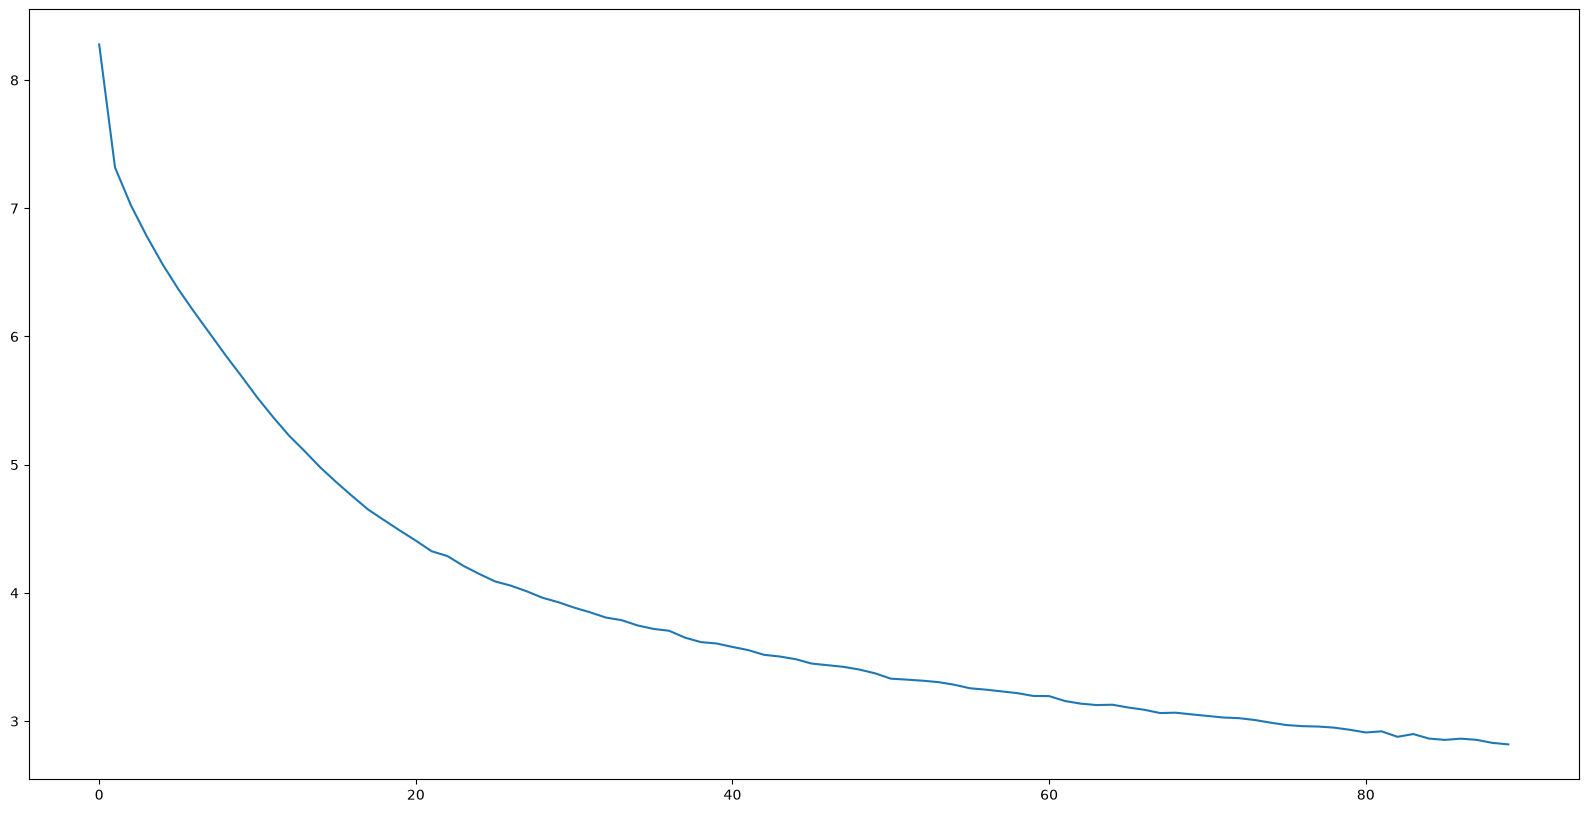

In [26]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(20, 10))
plt.plot(lossHist)
plt.show()

In [29]:
idxToText = {idx: word for word, idx in vocabulary.items()}
len(idxToText)

5378

In [31]:
def answerAnyQuiz(question, vocab, model, idxToText):

    model.eval()

    with torch.no_grad():

        question = textToIdx(sentance= question, vocabulary= vocab)

        if not question:
            return "<UNK>"

        question = torch.tensor([question], dtype= torch.int)

        answer = torch.argmax(model(question), dim = 1).item()

        return idxToText.get(answer, "<UNK>")


In [195]:
test_questions = [
    "Biggest mountain?",
    "Who wrote Hobbit?",
    "Who wrote Harry Potter?",
    "Smallest country?",
    "First human landed on the moon?",
    "Biggest river?",
    "Symbol of oxygen?",
    "Symbol of gold",
    "Symbol of iron?",
    "What is 100 divided by 4?",
    "Largest animal",
    "What is the holy book of Islam called?",
    "Capital of india?",
    "Biggest planet?",
    "Closest planet?",
    "Largest ocean",
    "Smallest bird?",
    "Which planet is known as the Red Planet?",
    "What is the largest planet in our solar system?",
    "What is the capital of Japan?",
    "Which star is closest to Earth?",
    "What is the chemical symbol for gold?",
    "Which animal is called the ship of the desert?",
    "What is the largest ocean?",
    "Which organ pumps blood throughout the body?",
    "What is the hardest natural substance?",
    "Which gas do humans need to breathe?",
    "What is the capital of Bangladesh?",
    "Which planet is famous for its rings?",
    "What is the natural satellite of Earth?",
    "Which metal is liquid at room temperature?",
    "What is the chemical formula H2O commonly called?",
    "Which continent contains Egypt?",
    "What is the fastest land animal?",
    "Who wrote Hamlet?",
    "What force pulls objects toward Earth?",
    "What is the freezing point of water in Celsius?"
]

for question in test_questions:
    print(f"{question:50} => {answerAnyQuiz(question= question, vocab= vocabulary, model= model, idxToText= idxToText).capitalize()}")

Biggest mountain?                                  => Everest
Who wrote Hobbit?                                  => Tolkien
Who wrote Harry Potter?                            => J
Smallest country?                                  => Vatican
First human landed on the moon?                    => Armstrong
Biggest river?                                     => Nile
Symbol of oxygen?                                  => O
Symbol of gold                                     => Au
Symbol of iron?                                    => Fe
What is 100 divided by 4?                          => 25
Largest animal                                     => Whale
What is the holy book of Islam called?             => Encryption
Capital of india?                                  => Newdelhi
Biggest planet?                                    => Jupiter
Closest planet?                                    => Mars
Largest ocean                                      => Pacific
Smallest bird?                       

In [70]:
torch.save(model.state_dict(), "quiz_ai.pth")

import json

with open("vocabulary.json", "w", encoding="utf-8") as f:
    json.dump(vocabulary, f, ensure_ascii=False)
